# Ejercicio 2: Simulación de un único rayo binario

In [1]:
# no se pq no me deja X_fantoma del ej1 lo hago d nuevo je

import numpy as np
import matplotlib.pyplot as plt
import os

X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = 8 #dimension 8x8 de la matrizx
x_fantoma = X_fantoma.reshape(-1)

## Inciso a)

In [2]:
def mascara_rayo(n, direccion, s):
    #   M[i,j] = 1  si  alpha*i + beta*j == s 
    #       si (el centro del píxel está sobre el rayo)
    alpha, beta = direccion
    i = np.arange(n).reshape(n, 1)   # varía con la fila
    j = np.arange(n).reshape(1, n)   # varía con la columna
    return (alpha * i + beta * j == s).astype(float)


# Chequeo contra el ejemplo de la Figura 6 del enunciado (n = 4).
M_r1 = mascara_rayo(4, (1, 1), 3)    # i + j = 3
M_r2 = mascara_rayo(4, (2, 1), 4)    # 2i + j = 4

print("r1:  i + j = 3")
print(M_r1.astype(int))
print("vectorizada:", M_r1.reshape(-1).astype(int))
print()
print("r2:  2i + j = 4")
print(M_r2.astype(int))
print("vectorizada:", M_r2.reshape(-1).astype(int))

r1:  i + j = 3
[[0 0 0 1]
 [0 0 1 0]
 [0 1 0 0]
 [1 0 0 0]]
vectorizada: [0 0 0 1 0 0 1 0 0 1 0 0 1 0 0 0]

r2:  2i + j = 4
[[0 0 0 0]
 [0 0 1 0]
 [1 0 0 0]
 [0 0 0 0]]
vectorizada: [0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0]


## Inciso b)

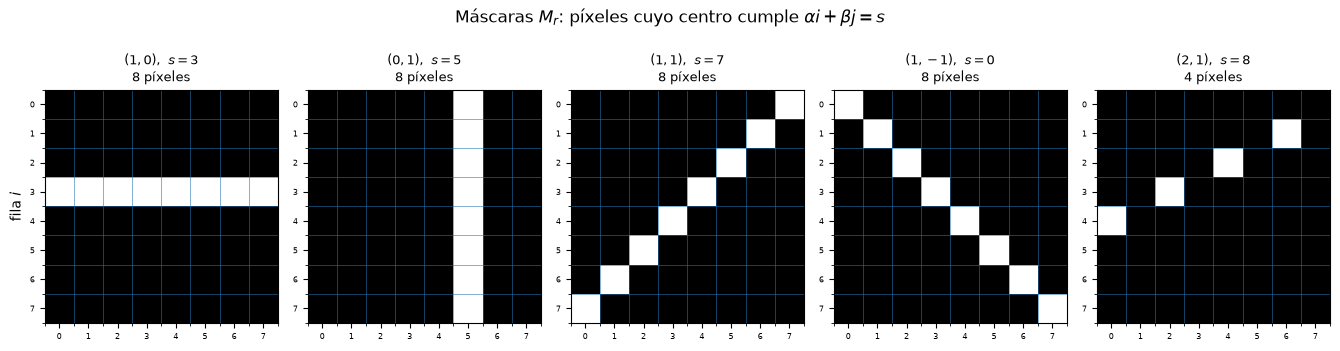

In [3]:
casos = [((1, 0), 3), ((0, 1), 5), ((1, 1), 7), ((1, -1), 0), ((2, 1), 8)]
# caso: (direccion, s)
mascaras = [mascara_rayo(n, d, s) for d, s in casos]
# mascaras: lista de mascaras M_r para cada caso

fig, axes = plt.subplots(1, 5, figsize=(13.5, 3.2))
for ax, M, (d, s) in zip(axes, mascaras, casos):
    ax.imshow(M, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"$({d[0]},{d[1]})$,  $s={s}$\n{int(M.sum())} píxeles", fontsize=9)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.tick_params(labelsize=6)
    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="tab:blue", lw=0.4)
axes[0].set_ylabel("fila $i$")
fig.suptitle(r"Máscaras $M_r$: píxeles cuyo centro cumple $\alpha i + \beta j = s$", y=1.06)
fig.tight_layout()
plt.show()

Se ve con claridad el rol de cada dirección:

- $(1,0)$ con $s=3$ da la ecuación $i = 3$: una **fila** completa.
- $(0,1)$ con $s=5$ da $j = 5$: una **columna** completa.
- $(1,1)$ con $s=7$ da $i+j=7$: la **antidiagonal** principal.
- $(1,-1)$ con $s=0$ da $i=j$: la **diagonal** principal.
- $(2,1)$ con $s=8$ da $2i+j=8$: una recta más inclinada que sólo pasa por $4$ centros,
  porque al avanzar una fila hay que retroceder dos columnas y muchos centros caen fuera de
  la grilla.

Nótese que la cantidad de píxeles por rayo **no** es constante: las direcciones "sencillas"
recogen $8$ píxeles, mientras que las inclinadas recogen bastante menos. Esto ya anticipa
que las direcciones $(2,1)$, $(1,2)$, $(3,1)$ aportan muchas ecuaciones, pero cada una con
poca información.

## Inciso c) 

In [4]:
print(f"{'dirección':>12} {'s':>4} {'#píxeles':>9} {'b_r (comp. a comp.)':>20} {'b_r (producto interno)':>22}")
b_valores = []
for M, (d, s) in zip(mascaras, casos):
    b_componentes = float((M * X_fantoma).sum())
    b_interno = float(M.reshape(-1) @ x_fantoma)
    b_valores.append(b_componentes)
    print(f"{str(d):>12} {s:>4} {int(M.sum()):>9} {b_componentes:>20.4f} {b_interno:>22.4f}")

   dirección    s  #píxeles  b_r (comp. a comp.) b_r (producto interno)
      (1, 0)    3         8               2.3000                 2.3000
      (0, 1)    5         8               2.4000                 2.4000
      (1, 1)    7         8               1.2000                 1.2000
     (1, -1)    0         8               1.9000                 1.9000
      (2, 1)    8         4               1.1000                 1.1000


## Inciso d)

#### ¿Por qué dos rayos con orientaciones diferentes pueden producir el mismo valor de medición, aunque seleccionen distintos píxeles?

Porque la medición no es el conjunto de píxeles, sino un solo número que es la suma de sus atenuaciones.